<a href="https://colab.research.google.com/github/jossykings/preventing-catastrophic-forgetting-using-experience-replay-and-EWC/blob/main/ewc_three_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

In [2]:
df = pd.read_csv('drive/MyDrive/Tasks_Binary/Task_1.csv')
df.head()

,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Binary_Label
0,0.0,0.0,14/02/2018 08:31:01,112641719.0,3.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,56320859.5,139.300036,56320958.0,56320761.0,Benign,0
1,0.0,0.0,14/02/2018 08:33:50,112641466.0,3.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,56320733.0,114.551299,56320814.0,56320652.0,Benign,0
2,0.0,0.0,14/02/2018 08:36:39,112638623.0,3.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,56319311.5,301.934596,56319525.0,56319098.0,Benign,0
3,22.0,6.0,14/02/2018 08:40:13,6453966.0,15.0,10.0,1239.0,2273.0,744.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign,0
4,22.0,6.0,14/02/2018 08:40:23,8804066.0,14.0,11.0,1143.0,2209.0,744.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign,0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df.columns

Index(['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts',
       'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg',
      

In [24]:
df.isnull().sum()

,0
Dst Port,0
Protocol,0
Timestamp,0
Flow Duration,0
Tot Fwd Pkts,0
...,...
Idle Std,0
Idle Max,0
Idle Min,0
Label,0


In [6]:
df['Dst Port']

,Dst Port
0,0.0
1,0.0
2,0.0
3,22.0
4,22.0
...,...
1275848,44358.0
1275849,80.0
1275850,44376.0
1275851,80.0


In [7]:
df['Protocol']

,Protocol
0,0.0
1,0.0
2,0.0
3,6.0
4,6.0
...,...
1275848,6.0
1275849,6.0
1275850,6.0
1275851,6.0


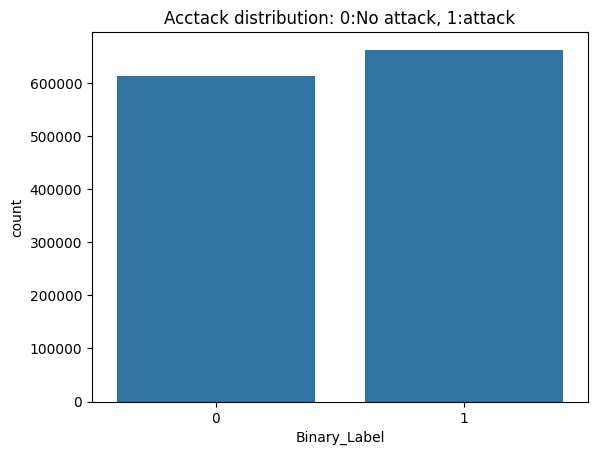

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Binary_Label',data=df)
plt.title('Acctack distribution: 0:No attack, 1:attack')
plt.show()

In [9]:
X_a = df.drop(columns=['Binary_Label','Label', 'Timestamp', 'Dst Port'])
y_a = df['Binary_Label']

columns_to_scale = [
    col for col in X_a.columns
    if not col.endswith('Flags')
    and not col.endswith('Flag Cnt')
    and col not in ['Protocol', 'CWE Flag Count']  # Exclude Protocol and the CWE flag
    and X_a[col].nunique() > 1                        # Drop constant columns (like Avg Block Rates)
]
columns_to_scale

['Flow Duration',
 'Tot Fwd Pkts',
 'Tot Bwd Pkts',
 'TotLen Fwd Pkts',
 'TotLen Bwd Pkts',
 'Fwd Pkt Len Max',
 'Fwd Pkt Len Min',
 'Fwd Pkt Len Mean',
 'Fwd Pkt Len Std',
 'Bwd Pkt Len Max',
 'Bwd Pkt Len Min',
 'Bwd Pkt Len Mean',
 'Bwd Pkt Len Std',
 'Flow Byts/s',
 'Flow Pkts/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Tot',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Tot',
 'Bwd IAT Mean',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd Header Len',
 'Bwd Header Len',
 'Fwd Pkts/s',
 'Bwd Pkts/s',
 'Pkt Len Min',
 'Pkt Len Max',
 'Pkt Len Mean',
 'Pkt Len Std',
 'Pkt Len Var',
 'Down/Up Ratio',
 'Pkt Size Avg',
 'Fwd Seg Size Avg',
 'Bwd Seg Size Avg',
 'Subflow Fwd Pkts',
 'Subflow Fwd Byts',
 'Subflow Bwd Pkts',
 'Subflow Bwd Byts',
 'Init Fwd Win Byts',
 'Init Bwd Win Byts',
 'Fwd Act Data Pkts',
 'Fwd Seg Size Min',
 'Active Mean',
 'Active Std',
 'Active Max',
 'Active Min',
 'Idle Mean',
 'Idle Std'

In [10]:
## lets go on to split our data

X_train_A,X_test_A, y_train_A, y_test_A = train_test_split(X_a,y_a, random_state=42, test_size=0.2, stratify=y_a)

In [11]:
X_train_A.shape,X_test_A.shape, y_train_A.shape, y_test_A.shape

((1020682, 77), (255171, 77), (1020682,), (255171,))

In [12]:
X_train_A_scaled = X_train_A.copy()
X_test_A_scaled = X_test_A.copy()

In [13]:
## we then scale our dataset correctly
scaler = RobustScaler()

X_train_A_scaled[columns_to_scale] = scaler.fit_transform(X_train_A_scaled[columns_to_scale])
X_test_A_scaled[columns_to_scale] = scaler.transform(X_test_A_scaled[columns_to_scale])

In [14]:
## now we would take a little sample of our data to train on for task one instead of making use of the entire dataset

X_train_smaller_A, _, y_train_smaller_A, _ = train_test_split(X_train_A_scaled,y_train_A, test_size=0.7, stratify=y_train_A, random_state=42)


X_train_smaller_A.shape, y_train_smaller_A.shape

((306204, 77), (306204,))

In [15]:
import pandas as pd

csv_path = "drive/MyDrive/Tasks_Binary/Task_2.csv"
chunk_size = 100000
TARGET_PER_CLASS = 200000  # Cap it at 200k rows per class (400k total)

threats_list = []
no_threats_list = []

threat_count = 0
no_threat_count = 0

print("Streaming and sampling on the fly...")
for chunk in pd.read_csv(csv_path, chunksize=chunk_size):
    chunk.columns = chunk.columns.str.strip()

    # 1. Filter out classes from the current chunk
    t_chunk = chunk[chunk['Binary_Label'] == 1]
    nt_chunk = chunk[chunk['Binary_Label'] == 0]

    # 2. Append threat rows if we haven't hit our target yet
    if threat_count < TARGET_PER_CLASS and not t_chunk.empty:
        needed = TARGET_PER_CLASS - threat_count
        sampled_t = t_chunk.head(needed) # take only what we need to hit the cap
        threats_list.append(sampled_t)
        threat_count += len(sampled_t)

    # 3. Append no-threat rows if we haven't hit our target yet
    if no_threat_count < TARGET_PER_CLASS and not nt_chunk.empty:
        needed = TARGET_PER_CLASS - no_threat_count
        sampled_nt = nt_chunk.head(needed)
        no_threats_list.append(sampled_nt)
        no_threat_count += len(sampled_nt)

    # 4. Break early if both buckets are full to save time!
    if threat_count >= TARGET_PER_CLASS and no_threat_count >= TARGET_PER_CLASS:
        print("Targets met early! Stopping stream.")
        break

# Combine the capped lists (instantly fast and memory-light)
df_threats_all = pd.concat(threats_list, ignore_index=True)
df_no_threats_all = pd.concat(no_threats_list, ignore_index=True)



Streaming and sampling on the fly...
Targets met early! Stopping stream.


In [16]:
# 1. Determine the smaller class size to achieve a perfect 50/50 ratio
target_sample_size = min(len(df_threats_all), len(df_no_threats_all))
print(f"Sampling {target_sample_size} rows from each class for a balanced set...")

# 2. Downsample the majority class to match the minority class perfectly
df_threats_balanced = df_threats_all.sample(n=target_sample_size, random_state=42)
df_no_threats_balanced = df_no_threats_all.sample(n=target_sample_size, random_state=42)

# 3. Concatenate them together and shuffle the rows completely
balanced_task2_df = pd.concat([df_threats_balanced, df_no_threats_balanced]).sample(frac=1, random_state=42).reset_index(drop=True)

# 4. Separate features (X) and target (y)
X_task2 = balanced_task2_df.drop(columns=['Binary_Label','Label', 'Timestamp', 'Dst Port'])
y_task2 = balanced_task2_df['Binary_Label']

# 5. Perform your Train-Test split on this safe, balanced dataset
X_train_t2, X_test_t2, y_train_B, y_test_B = train_test_split(
    X_task2, y_task2, test_size=0.20, stratify=y_task2, random_state=42
)

print(f"Task 2 training shape: {X_train_t2.shape}")
print(f"Task 2 testing shape: {X_test_t2.shape}")

Sampling 200000 rows from each class for a balanced set...
Task 2 training shape: (320000, 77)
Task 2 testing shape: (80000, 77)


In [17]:
from sklearn.preprocessing import RobustScaler

# 1. Initialize a completely new scaler instance for Task 2
scaler_task2 = RobustScaler()

# 2. Re-use your finalized columns_to_scale list from Task 1

X_train_B_scaled = X_train_t2.copy()
X_test_B_scaled = X_test_t2.copy()

# 3. Fit on Task 2 training data and transform both sets
X_train_B_scaled[columns_to_scale] = scaler_task2.fit_transform(X_train_t2[columns_to_scale])
X_test_B_scaled[columns_to_scale] = scaler_task2.transform(X_test_t2[columns_to_scale])

X_train_B_scaled.shape, y_train_B.shape, X_test_B_scaled.shape, y_test_B.shape

((320000, 77), (320000,), (80000, 77), (80000,))

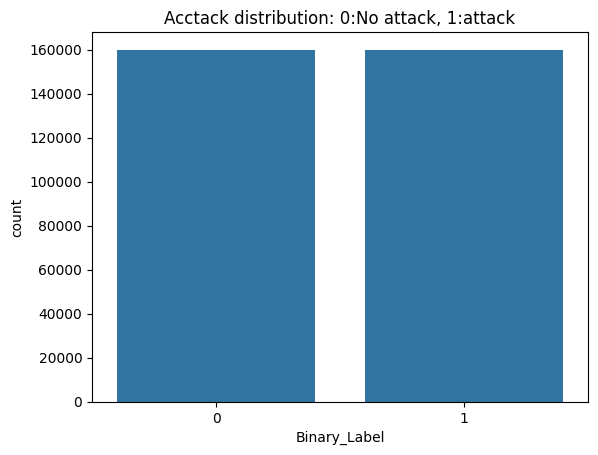

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=y_train_B)
plt.title('Acctack distribution: 0:No attack, 1:attack')
plt.show()

In [19]:
import pandas as pd

csv_path_3 = "drive/MyDrive/Tasks_Binary/Task_3.csv"
chunk_size = 100000
TARGET_PER_CLASS = 200000  # Cap it at 200k rows per class (400k total)

threats_list = []
no_threats_list = []

threat_count = 0
no_threat_count = 0

print("Streaming and sampling on the fly...")
for chunk in pd.read_csv(csv_path, chunksize=chunk_size):
    chunk.columns = chunk.columns.str.strip()

    # 1. Filter out classes from the current chunk
    t_chunk = chunk[chunk['Binary_Label'] == 1]
    nt_chunk = chunk[chunk['Binary_Label'] == 0]

    # 2. Append threat rows if we haven't hit our target yet
    if threat_count < TARGET_PER_CLASS and not t_chunk.empty:
        needed = TARGET_PER_CLASS - threat_count
        sampled_t = t_chunk.head(needed) # take only what we need to hit the cap
        threats_list.append(sampled_t)
        threat_count += len(sampled_t)

    # 3. Append no-threat rows if we haven't hit our target yet
    if no_threat_count < TARGET_PER_CLASS and not nt_chunk.empty:
        needed = TARGET_PER_CLASS - no_threat_count
        sampled_nt = nt_chunk.head(needed)
        no_threats_list.append(sampled_nt)
        no_threat_count += len(sampled_nt)

    # 4. Break early if both buckets are full to save time!
    if threat_count >= TARGET_PER_CLASS and no_threat_count >= TARGET_PER_CLASS:
        print("Targets met early! Stopping stream.")
        break

# Combine the capped lists (instantly fast and memory-light)
df_threats_all = pd.concat(threats_list, ignore_index=True)
df_no_threats_all = pd.concat(no_threats_list, ignore_index=True)



Streaming and sampling on the fly...
Targets met early! Stopping stream.


In [20]:
# 1. Determine the smaller class size to achieve a perfect 50/50 ratio
target_sample_size = min(len(df_threats_all), len(df_no_threats_all))
print(f"Sampling {target_sample_size} rows from each class for a balanced set...")

# 2. Downsample the majority class to match the minority class perfectly
df_threats_balanced = df_threats_all.sample(n=target_sample_size, random_state=42)
df_no_threats_balanced = df_no_threats_all.sample(n=target_sample_size, random_state=42)

# 3. Concatenate them together and shuffle the rows completely
balanced_task3_df = pd.concat([df_threats_balanced, df_no_threats_balanced]).sample(frac=1, random_state=42).reset_index(drop=True)

# 4. Separate features (X) and target (y)
X_task3 = balanced_task3_df.drop(columns=['Binary_Label','Label', 'Timestamp', 'Dst Port'])
y_task3 = balanced_task3_df['Binary_Label']

# 5. Perform your Train-Test split on this safe, balanced dataset
X_train_t3, X_test_t3, y_train_C, y_test_C = train_test_split(
    X_task3, y_task3, test_size=0.20, stratify=y_task2, random_state=42
)

print(f"Task 2 training shape: {X_train_t3.shape}")
print(f"Task 2 testing shape: {X_test_t3.shape}")

Sampling 200000 rows from each class for a balanced set...
Task 2 training shape: (320000, 77)
Task 2 testing shape: (80000, 77)


In [21]:
from sklearn.preprocessing import RobustScaler

# 1. Initialize a completely new scaler instance for Task 2
scaler_task3 = RobustScaler()

# 2. Re-use your finalized columns_to_scale list from Task 1

X_train_C_scaled = X_train_t3.copy()
X_test_C_scaled = X_test_t3.copy()

# 3. Fit on Task 2 training data and transform both sets
X_train_C_scaled[columns_to_scale] = scaler_task3.fit_transform(X_train_t3[columns_to_scale])
X_test_C_scaled[columns_to_scale] = scaler_task3.transform(X_test_t3[columns_to_scale])

X_train_C_scaled.shape, y_train_C.shape, X_test_C_scaled.shape, y_test_C.shape

((320000, 77), (320000,), (80000, 77), (80000,))

## EWC implementation
**What the experiment does** (run twice: once with `ewc=False`, once with `ewc=True`):

| Stage | Train on | Then test on |
|---|---|---|
| 1 | Task A | A, B, C |
| 2 | Task B | A, B, C |
| 3 | Task C | A, B, C |

Metrics: **accuracy, precision, recall** (the "positive" class is `1` = attack).
Both runs start from the same initial weights, so any difference is down to EWC.

**How EWC enters:** after finishing each task with `ewc=True`, `train_task` stores that task's weights (θ\*) and Fisher importance. When training the next task, the loss becomes `loss = cross_entropy + (λ/2) Σ F·(θ − θ*)²`, summed over every earlier task.

In [22]:
##Metrices to make use of to test our model
from sklearn.metrics import accuracy_score, precision_score, recall_score

SEED   = 42
EPOCHS = 5        # epochs per task
BATCH  = 512
LAM    = 10.0       # EWC strength: the main knob (see the optional sweep at the end)

### Hand your prepared data to the experiment (uses your variable names)

In [26]:
import numpy as np
##The CICIDS/CSE-CIC-IDS datasets are famous for this exact bug. When Flow Duration is 0, dividing packet counts or bytes by the duration produces inf or nan inside Flow Byts/s and Flow Pkts/s.

# List your datasets to clean them all in one go
datasets_X = [X_train_smaller_A, X_train_B_scaled, X_train_C_scaled]
datasets_y = [y_train_smaller_A, y_train_B, y_train_C]

cleaned_X = []
cleaned_y = []

for X, y in zip(datasets_X, datasets_y):
    # Convert scaled numpy arrays back to DataFrame if necessary to map indices smoothly
    if isinstance(X, np.ndarray):
        # Use the original DataFrame columns or index if you have them,
        # otherwise wrap it to clean infinite values
        X_df = pd.DataFrame(X)
    else:
        X_df = X.copy()

    # Replace infinity with NaN
    X_df = X_df.replace([np.inf, -np.inf], np.nan)

    # Track rows that do NOT contain any NaNs
    valid_rows_mask = X_df.notna().all(axis=1)

    # Filter both X and y to keep only clean rows
    X_clean = X_df[valid_rows_mask]
    y_clean = y[valid_rows_mask.values] # Keeps y aligned perfectly

    cleaned_X.append(X_clean)
    cleaned_y.append(y_clean)

# Assign your cleaned variables back
X_train_smaller_A_clean, X_train_B_scaled_clean, X_train_C_scaled_clean = cleaned_X
y_train_smaller_A_clean, y_train_B_clean, y_train_C_clean = cleaned_y

In [27]:
## have this also done for test dataset

import numpy as np
import pandas as pd

# List your test datasets
datasets_X_test = [X_test_A_scaled, X_test_B_scaled, X_test_C_scaled]
datasets_y_test = [y_test_A, y_test_B, y_test_C]

cleaned_X_test = []
cleaned_y_test = []

for X, y in zip(datasets_X_test, datasets_y_test):
    # Convert to DataFrame if it's already a raw numpy array
    X_df = pd.DataFrame(X) if isinstance(X, np.ndarray) else X.copy()

    # 1. Replace infs with NaN
    X_df = X_df.replace([np.inf, -np.inf], np.nan)

    # 2. Find rows that are fully valid (finite)
    valid_rows_mask = X_df.notna().all(axis=1)

    # 3. Drop contaminated rows from BOTH features and labels
    X_clean = X_df[valid_rows_mask]
    y_clean = y[valid_rows_mask.values] if hasattr(y, 'values') else y[valid_rows_mask]

    cleaned_X_test.append(X_clean)
    cleaned_y_test.append(y_clean)

# Assign your clean test sets back
X_test_A_clean, X_test_B_clean, X_test_C_clean = cleaned_X_test
y_test_A_clean, y_test_B_clean, y_test_C_clean = cleaned_y_test


In [29]:
cols = list(X_train_smaller_A.columns)            # one fixed column order for every task

def arr(X):
    a = X[cols].to_numpy("float32")
    assert np.isfinite(a).all(), "NaN/inf found: clean these first (e.g. 'Flow Byts/s', 'Flow Pkts/s')"
    return a

NAMES = ["A", "B", "C"]
TRAIN = {
    "A": (arr(X_train_smaller_A_clean), y_train_smaller_A_clean.to_numpy("float32")),
    "B": (arr(X_train_B_scaled_clean),  y_train_B_clean.to_numpy("float32")),
    "C": (arr(X_train_C_scaled_clean),  y_train_C_clean.to_numpy("float32"))
}
TEST = {
    "A": (arr(X_test_A_clean), y_test_A_clean.to_numpy("float32")),
    "B": (arr(X_test_B_clean), y_test_B_clean.to_numpy("float32")),
    "C": (arr(X_test_C_clean), y_test_C_clean.to_numpy("float32"))
}

for n in NAMES:
    print(f"Task {n}: train {TRAIN[n][0].shape} (attack share {TRAIN[n][1].mean():.2f}) | "
          f"test {TEST[n][0].shape} (attack share {TEST[n][1].mean():.2f})")

Task A: train (305883, 77) (attack share 0.52) | test (254925, 77) (attack share 0.52)
Task B: train (319041, 77) (attack share 0.50) | test (79756, 77) (attack share 0.50)
Task C: train (319041, 77) (attack share 0.50) | test (79756, 77) (attack share 0.50)


### Model
our architecture (128 → 64 → 32 → 1), with two small changes that matter for EWC:
- **No BatchNorm.** Its running mean/variance are not trainable weights, so the EWC penalty cannot hold them, and they would silently drift while training on the next task.
- **The last layer outputs a raw logit** (sigmoid is applied in the loss and when predicting). It is numerically safer and lets the Fisher be computed exactly.

In [30]:
def build_model(n_features):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(128, activation="relu"), tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),  tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1),                       # raw logit
    ])

def evaluate(model, X, y):
    p = tf.sigmoid(model.predict(X, batch_size=8192, verbose=0)[:, 0]).numpy()
    pred = (p >= 0.5).astype(int)
    return {"accuracy":  accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall":    recall_score(y, pred, zero_division=0)}

### The EWC pieces
- `compute_fisher`: how much each weight mattered for the task just learned. For a binary output this has an exact form: `F = p(1−p) · (∂logit/∂weight)²`, averaged over a sample of that task's data. It is rescaled to average 1, so `LAM` means the same thing whatever the model's confidence.
- `ewc_penalty`: `(λ/2) Σ F·(θ − θ*)²` for every previously learned task.
- `train_task(..., ewc=True/False)`: we could toggle this off and o so we could test to see before having EWC and after having EWC.

In [31]:
def compute_fisher(model, X, n_samples=2000, batch=100, seed=SEED):
    idx = np.random.RandomState(seed).choice(len(X), min(n_samples, len(X)), replace=False)
    Xs = tf.constant(X[idx])
    variables = model.trainable_variables

    @tf.function(reduce_retracing=True)
    def batch_fisher(xb):
        with tf.GradientTape() as tape:
            z = model(xb, training=False)[:, 0]                          # logits
        jac = tape.jacobian(z, variables)                                # per-sample gradient of each logit
        w = tf.sigmoid(z) * (1 - tf.sigmoid(z))                          # Bernoulli variance p(1-p)
        return [tf.reduce_sum(tf.reshape(w, [-1] + [1] * (len(j.shape) - 1)) * tf.square(j), axis=0)
                for j in jac]

    fisher = [tf.zeros_like(v) for v in variables]
    for s in range(0, len(Xs), batch):
        fisher = [f + g for f, g in zip(fisher, batch_fisher(Xs[s:s + batch]))]
    fisher = [f / len(Xs) for f in fisher]
    mean_f = sum(float(tf.reduce_sum(f)) for f in fisher) / sum(int(tf.size(f)) for f in fisher)
    return [f / mean_f for f in fisher]                                  # rescale: average importance = 1

def ewc_penalty(model, fishers, anchors, lam):
    total = tf.constant(0.0)
    for fisher, anchor in zip(fishers, anchors):                         # every earlier task
        for f, a, v in zip(fisher, anchor, model.trainable_variables):
            total += tf.reduce_sum(f * tf.square(v - a))
    return 0.5 * lam * total

def train_task(model, X, y, ewc=False, memory=None, lam=LAM, epochs=EPOCHS,
               batch_size=BATCH, lr=1e-3, verbose=True):
    """Train on one task.
    ewc=False -> plain training.
    ewc=True  -> add the EWC penalty for all earlier tasks held in `memory`, and afterwards store
                 this task's Fisher + weights in `memory` for the tasks that follow."""
    fishers = list(memory["fishers"]) if ewc else []
    anchors = list(memory["anchors"]) if ewc else []
    opt = tf.keras.optimizers.Adam(lr)

    @tf.function
    def step(xb, yb):
        with tf.GradientTape() as tape:
            z = model(xb, training=True)[:, 0]
            ce = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=yb, logits=z))
            pen = ewc_penalty(model, fishers, anchors, lam)              # 0 when there are no earlier tasks
            loss = ce + pen                                              # <- EWC enters HERE
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return ce, pen

    ds = (tf.data.Dataset.from_tensor_slices((X, y)).shuffle(len(X), seed=SEED)
          .batch(batch_size).prefetch(tf.data.AUTOTUNE))
    for epoch in range(epochs):
        ce_sum, pen_sum, n = 0.0, 0.0, 0
        for xb, yb in ds:
            ce, pen = step(xb, yb); ce_sum += ce; pen_sum += pen; n += 1
        if verbose:
            print(f"    epoch {epoch + 1}/{epochs}  loss={float(ce_sum) / n:.4f}  ewc_penalty={float(pen_sum) / n:.4f}")

    if ewc:                                                              # consolidate this task
        memory["fishers"].append(compute_fisher(model, X))
        memory["anchors"].append([tf.identity(v) for v in model.trainable_variables])

### Run the whole sequence
After training on each task (A, then B, then C), the model is tested on **all three** tasks.

In [32]:
def run_sequence(ewc, lam=LAM, verbose=True):
    tf.keras.utils.set_random_seed(SEED)                  # same starting weights for every run
    model = build_model(len(cols))
    memory = {"fishers": [], "anchors": []}
    rows = []
    for trained in NAMES:
        if verbose: print(f"  Training on Task {trained}  (ewc={ewc})")
        train_task(model, *TRAIN[trained], ewc=ewc, memory=memory, lam=lam, verbose=verbose)
        for tested in NAMES:
            rows.append({"trained_through": trained, "tested_on": tested, **evaluate(model, *TEST[tested])})
    return pd.DataFrame(rows)

print("=== WITHOUT EWC ===");  res_plain = run_sequence(ewc=False)
print("\n=== WITH EWC ===");    res_ewc   = run_sequence(ewc=True)

=== WITHOUT EWC ===
  Training on Task A  (ewc=False)
    epoch 1/5  loss=10508.7893  ewc_penalty=0.0000
    epoch 2/5  loss=363.3101  ewc_penalty=0.0000
    epoch 3/5  loss=68.3363  ewc_penalty=0.0000
    epoch 4/5  loss=19.9058  ewc_penalty=0.0000
    epoch 5/5  loss=14.4971  ewc_penalty=0.0000
  Training on Task B  (ewc=False)
    epoch 1/5  loss=6.7207  ewc_penalty=0.0000
    epoch 2/5  loss=1.2734  ewc_penalty=0.0000
    epoch 3/5  loss=0.2602  ewc_penalty=0.0000
    epoch 4/5  loss=0.5045  ewc_penalty=0.0000
    epoch 5/5  loss=0.9419  ewc_penalty=0.0000
  Training on Task C  (ewc=False)
    epoch 1/5  loss=1.5969  ewc_penalty=0.0000
    epoch 2/5  loss=1.2142  ewc_penalty=0.0000
    epoch 3/5  loss=1.3572  ewc_penalty=0.0000
    epoch 4/5  loss=0.8953  ewc_penalty=0.0000
    epoch 5/5  loss=0.2365  ewc_penalty=0.0000

=== WITH EWC ===
  Training on Task A  (ewc=True)
    epoch 1/5  loss=10508.7901  ewc_penalty=0.0000
    epoch 2/5  loss=359.9365  ewc_penalty=0.0000
    epoch 3/5

### 1. After training on Task A only: the model tested on A, B and C
This is the same for both runs (EWC has nothing to protect yet), and shows how little Task A's model knows about B and C.

In [33]:
display(res_plain[res_plain.trained_through == "A"].drop(columns="trained_through").set_index("tested_on").round(3))

,accuracy,precision,recall
tested_on,,,
A,0.953,0.97,0.939
B,0.891,0.92,0.858
C,0.891,0.92,0.858


### 2. Every stage, every test set
Rows are the metric, columns are the task being tested. The x-axis is *which task the model has been trained through*. The dashed line marks when that column's task was learned. **Red = no EWC, green = EWC.** After the dashed line, a falling red line is forgetting, and a green line that stays up is EWC working.

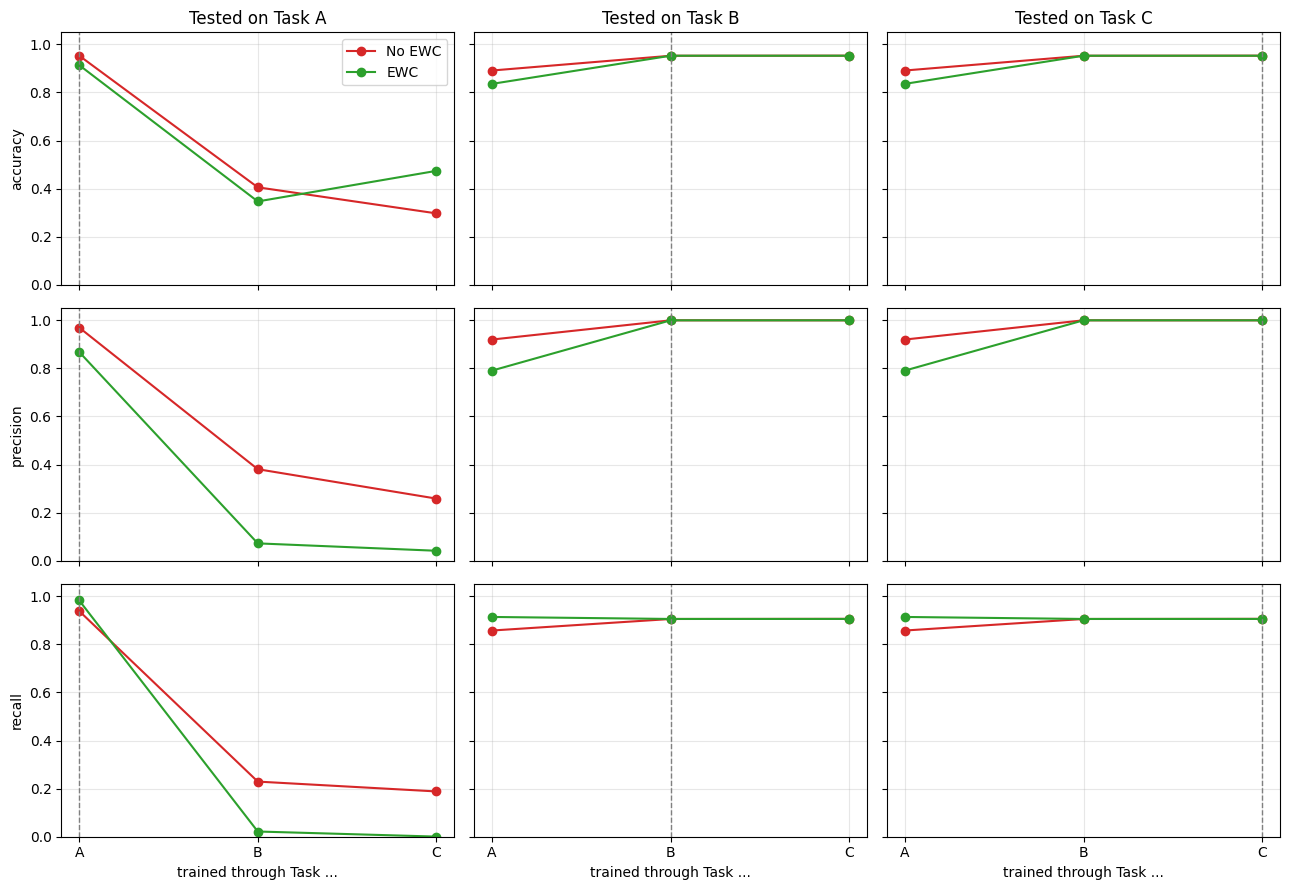

In [34]:
metrics = ["accuracy", "precision", "recall"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True, sharey=True)
for i, m in enumerate(metrics):
    for j, t in enumerate(NAMES):
        ax = axes[i, j]
        for label, df, col in (("No EWC", res_plain, "tab:red"), ("EWC", res_ewc, "tab:green")):
            d = df[df.tested_on == t]
            ax.plot(d.trained_through, d[m], "o-", c=col, label=label)
        ax.axvline(j, ls="--", c="gray", lw=1)
        ax.set_ylim(0, 1.05); ax.grid(alpha=.3)
        if i == 0: ax.set_title(f"Tested on Task {t}")
        if j == 0: ax.set_ylabel(m)
        if i == 2: ax.set_xlabel("trained through Task ...")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

### 3. Final result, after all three tasks

In [35]:
both = pd.concat({"No EWC": res_plain, "EWC": res_ewc}, names=["method"]).reset_index(level=0)
last = both[both.trained_through == "C"].pivot(index="tested_on", columns="method", values=metrics)
last.loc["average"] = last.mean()
display(last.round(3))

accuracy        precision        recall       
method         EWC No EWC       EWC No EWC    EWC No EWC
tested_on                                               
A            0.474  0.297     0.042  0.258  0.001  0.188
B            0.953  0.953     1.000  1.000  0.906  0.906
C            0.953  0.953     1.000  1.000  0.906  0.906
average      0.793  0.734     0.681  0.753  0.604  0.667

### 4. How much did each earlier task lose?
For Tasks A and B: the score right after learning the task vs after Task C has been trained.

In [36]:
rows = []
for label, df in (("No EWC", res_plain), ("EWC", res_ewc)):
    for t in ["A", "B"]:
        just = df[(df.trained_through == t) & (df.tested_on == t)].iloc[0]
        end  = df[(df.trained_through == "C") & (df.tested_on == t)].iloc[0]
        rows.append({"method": label, "task": t,
                     "accuracy just learned": just.accuracy, "accuracy after C": end.accuracy,
                     "accuracy lost": just.accuracy - end.accuracy,
                     "recall just learned": just.recall, "recall after C": end.recall,
                     "recall lost": just.recall - end.recall})
display(pd.DataFrame(rows).set_index(["method", "task"]).round(3))

accuracy just learned  accuracy after C  accuracy lost  \
method task                                                           
No EWC A                     0.953             0.297          0.656   
       B                     0.953             0.953         -0.000   
EWC    A                     0.914             0.474          0.440   
       B                     0.953             0.953         -0.000   

             recall just learned  recall after C  recall lost  
method task                                                    
No EWC A                   0.939           0.188        0.751  
       B                   0.906           0.906       -0.001  
EWC    A                   0.983           0.001        0.982  
       B                   0.906           0.906       -0.000

## Notes
- **Different scalers per task.** Each of your tasks is scaled with its own `RobustScaler`, so the same raw feature value maps to different inputs in different tasks. That is fine for this experiment, but a deployed model would need one scaler (for example, the one fitted on Task A) because it can't know which task a new record belongs to.
- **Accuracy on imbalanced test sets can look good by predicting "no attack" every time.** That is why precision and recall are shown too; watch **recall** to see whether attacks are still being caught.
- Typo in your old compile cell: `tf.kera.optimizers` should be `tf.keras.optimizers`. It no longer matters here because training uses `train_task`.